In [7]:
#Check the dataset path


import os

dataset_path = r"C:\Users\P VARSHITHA REDDY\Downloads\archive\plantvillage dataset\color"

print("Exists:", os.path.exists(dataset_path))
print("Path:", dataset_path)

Exists: True
Path: C:\Users\P VARSHITHA REDDY\Downloads\archive\plantvillage dataset\color


In [8]:
#Check the 36 classes

classes = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]

print("Total classes:", len(classes))

for i, folder in enumerate(sorted(classes), 1):
    print(i, ":", folder)

Total classes: 36
1 : Apple___Apple_scab
2 : Apple___Black_rot
3 : Apple___Cedar_apple_rust
4 : Apple___healthy
5 : Blueberry___healthy
6 : Cherry_(including_sour)___Powdery_mildew
7 : Cherry_(including_sour)___healthy
8 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
9 : Corn_(maize)___Common_rust_
10 : Corn_(maize)___Northern_Leaf_Blight
11 : Corn_(maize)___healthy
12 : Grape___Black_rot
13 : Grape___Esca_(Black_Measles)
14 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15 : Grape___healthy
16 : Orange___Haunglongbing_(Citrus_greening)
17 : Peach___Bacterial_spot
18 : Peach___healthy
19 : Pepper,_bell___Bacterial_spot
20 : Pepper,_bell___healthy
21 : Potato___Early_blight
22 : Potato___Late_blight
23 : Potato___healthy
24 : Raspberry___healthy
25 : Soybean___healthy
26 : Squash___Powdery_mildew
27 : Strawberry___Leaf_scorch
28 : Strawberry___healthy
29 : Tomato___Bacterial_spot
30 : Tomato___Early_blight
31 : Tomato___Late_blight
32 : Tomato___Leaf_Mold
33 : Tomato___Septoria_leaf

In [9]:
#Count images


class_counts = {}

for folder in classes:
    folder_path = os.path.join(dataset_path, folder)

    images = [
        file for file in os.listdir(folder_path)
        if file.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    class_counts[folder] = len(images)

print("Total images:", sum(class_counts.values()))

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

Total images: 52341
Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1162
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Grape___healthy: 423
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacterial_spot: 2297
Peach___healthy: 360
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1478
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5090
Squash___Powdery_mildew: 1835
Strawberry___Leaf_scorch: 1109
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato___Late_blight: 1909
Tomato___Leaf_Mold: 9

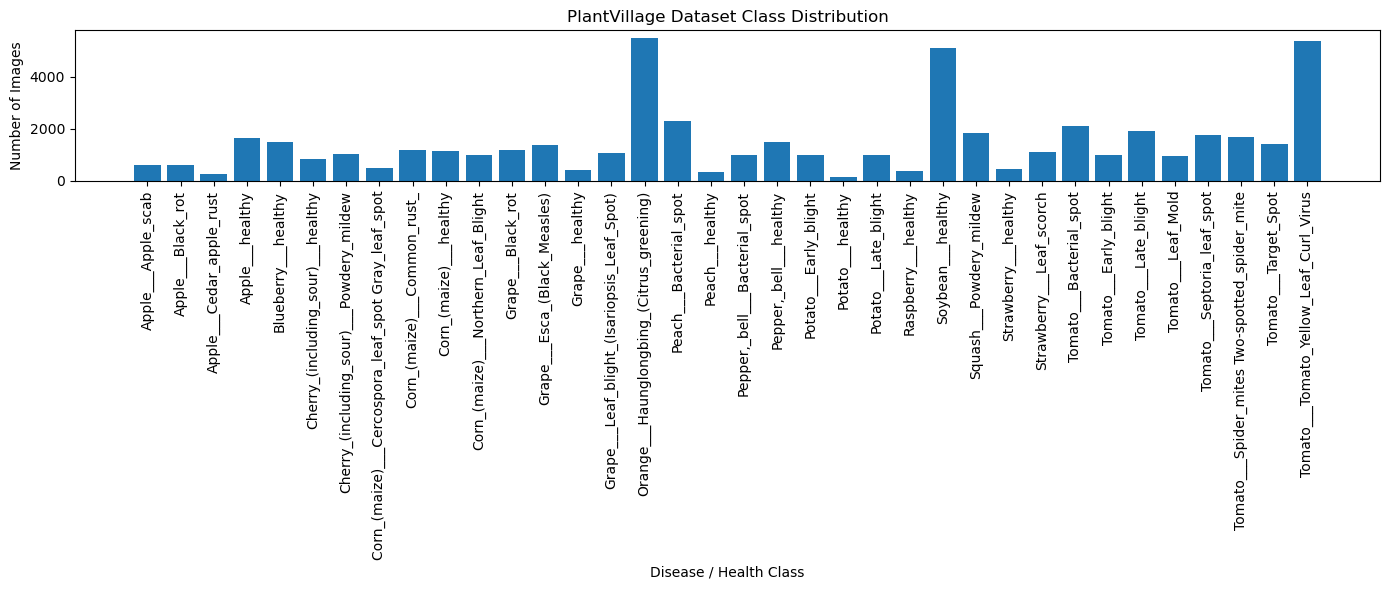

In [10]:
#how many images each disease class contains.

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.xticks(rotation=90)
plt.xlabel("Disease / Health Class")
plt.ylabel("Number of Images")
plt.title("PlantVillage Dataset Class Distribution")

plt.tight_layout()
plt.show()

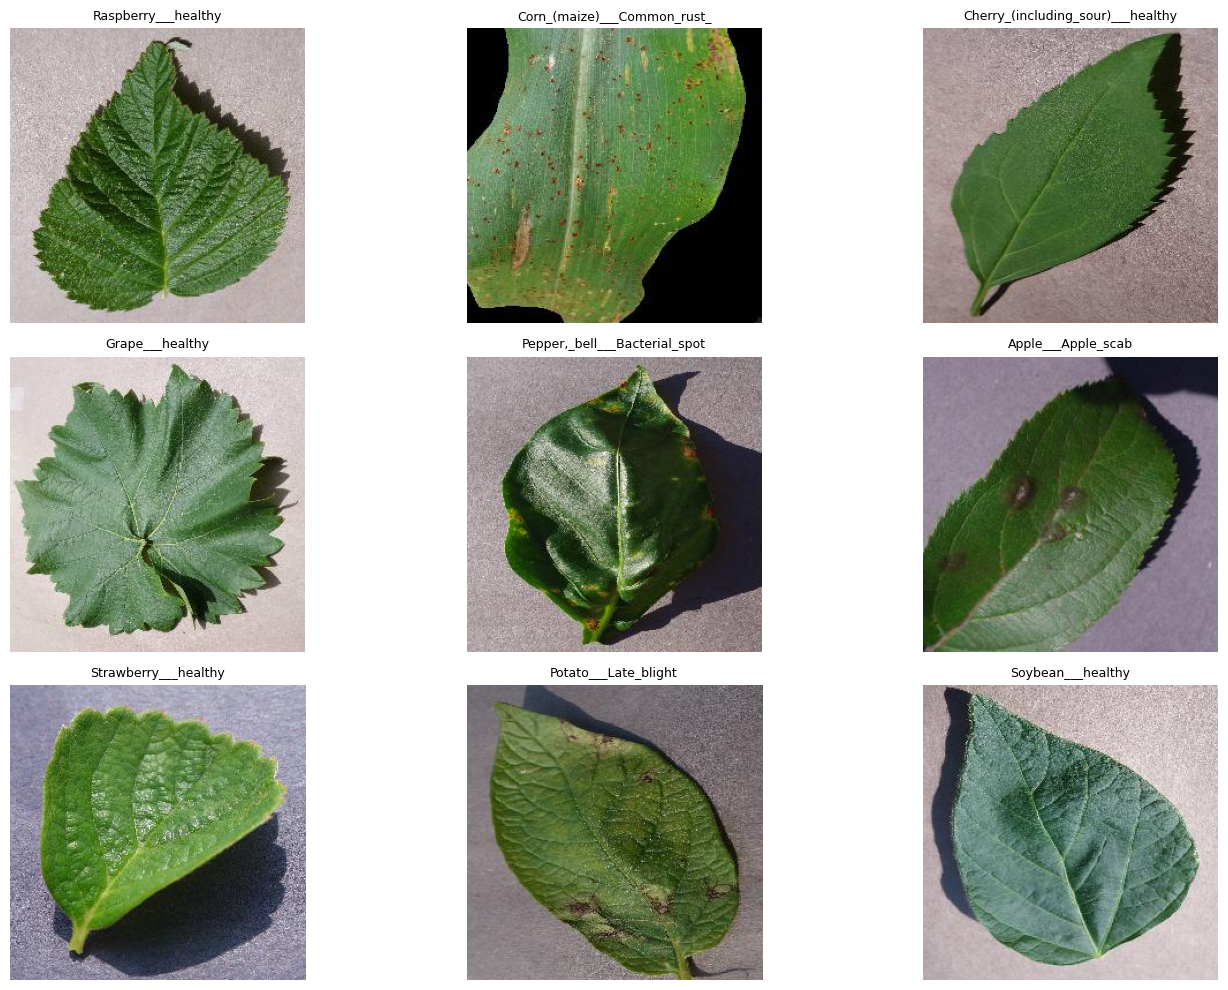

In [11]:
#Display sample images

import random
from PIL import Image

plt.figure(figsize=(15, 10))

sample_classes = random.sample(classes, 9)

for i, class_name in enumerate(sample_classes):
    folder_path = os.path.join(dataset_path, class_name)

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    image_file = random.choice(image_files)
    image_path = os.path.join(folder_path, image_file)

    image = Image.open(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
#Check one image size

sample_class = classes[0]

folder_path = os.path.join(dataset_path, sample_class)

image_files = [
    f for f in os.listdir(folder_path)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

sample_image = Image.open(
    os.path.join(folder_path, image_files[0])
)

print("Class:", sample_class)
print("Image size:", sample_image.size)
print("Image mode:", sample_image.mode)

Class: Apple___Apple_scab
Image size: (256, 256)
Image mode: RGB


In [7]:
!pip install tensorflow

In [13]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [22]:
#checking the dataset before data cleaning
#how many disease classes you have
#the names of the classes
#total number of images

import os

# Change this only if your dataset path is different
dataset_path = r"C:\Users\P VARSHITHA REDDY\Downloads\archive\plantvillage dataset\color"

# Count classes
classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Number of classes:", len(classes))
print("\nFirst 10 classes:")
for cls in classes[:10]:
    print(cls)

# Count total images
total_images = 0

for cls in classes:
    class_path = os.path.join(dataset_path, cls)
    total_images += len([
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

print("\nTotal images:", total_images)

Number of classes: 36

First 10 classes:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight

Total images: 52341


In [23]:
#Corrupted images

from PIL import Image
import os

valid_extensions = (".jpg", ".jpeg", ".png")

total_images = 0
valid_images = 0
corrupted_images = []

for class_name in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):

        if not filename.lower().endswith(valid_extensions):
            continue

        total_images += 1
        image_path = os.path.join(class_path, filename)

        try:
            with Image.open(image_path) as img:
                img.verify()

            valid_images += 1

        except Exception:
            corrupted_images.append(image_path)

print("Total images:", total_images)
print("Valid images:", valid_images)
print("Corrupted images:", len(corrupted_images))

if corrupted_images:
    print("\nFirst 10 corrupted images:")
    for image in corrupted_images[:10]:
        print(image)

Total images: 52341
Valid images: 52341
Corrupted images: 0


In [24]:
#load and preprocess the dataset

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names

print("Number of classes:", len(class_names))
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())

Found 54305 files belonging to 36 classes.
Using 43444 files for training.
Found 54305 files belonging to 36 classes.
Using 10861 files for validation.
Number of classes: 36
Training batches: 1358
Validation batches: 340


In [26]:
#find the files TensorFlow is counting

import os

# Count every file inside the 36 class folders
all_files = []
image_files = []

for class_name in os.listdir(dataset_path):
    class_path = os.path.join(dataset_path, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        full_path = os.path.join(class_path, filename)

        if os.path.isfile(full_path):
            all_files.append(full_path)

            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                image_files.append(full_path)

print("All files inside class folders:", len(all_files))
print("JPG/JPEG/PNG files:", len(image_files))
print("Other files:", len(all_files) - len(image_files))

print("\nOther files:")
for file in all_files:
    if file not in image_files:
        print(file)

All files inside class folders: 52341
JPG/JPEG/PNG files: 52341
Other files: 0

Other files:


In [27]:
#create the correct 80/20 split

import os
import random

# Collect all verified image paths and their class labels
image_paths = []
labels = []

class_names = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)

    for filename in os.listdir(class_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(class_path, filename))
            labels.append(class_to_index[class_name])

# Shuffle paths and labels together
combined = list(zip(image_paths, labels))
random.seed(42)
random.shuffle(combined)

image_paths, labels = zip(*combined)

image_paths = list(image_paths)
labels = list(labels)

# 80/20 split
split_index = int(0.8 * len(image_paths))

train_paths = image_paths[:split_index]
train_labels = labels[:split_index]

validation_paths = image_paths[split_index:]
validation_labels = labels[split_index:]

print("Total images:", len(image_paths))
print("Training images:", len(train_paths))
print("Validation images:", len(validation_paths))
print("Number of classes:", len(class_names))

Total images: 52341
Training images: 41872
Validation images: 10469
Number of classes: 36


In [28]:
#create TensorFlow datasets

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


train_path_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

validation_path_ds = tf.data.Dataset.from_tensor_slices(
    (validation_paths, validation_labels)
)

train_dataset = train_path_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_dataset = validation_path_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

validation_dataset = validation_dataset.batch(BATCH_SIZE).prefetch(
    tf.data.AUTOTUNE
)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training batches:",
      tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:",
      tf.data.experimental.cardinality(validation_dataset).numpy())

Image size: (224, 224)
Batch size: 32
Training batches: 1309
Validation batches: 328


In [7]:
#resize, normalize, and split data.
# data augmentation to train data only

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

print("Data augmentation created successfully.")

Data augmentation created successfully.


In [30]:
# Prepare a smaller image representation for Logistic Regression

LR_IMG_SIZE = (64, 64)

def prepare_lr_dataset(paths, labels):
    images = []

    for path in paths:
        image = tf.io.read_file(path)
        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )
        image = tf.image.resize(image, LR_IMG_SIZE)
        image = tf.cast(image, tf.float32) / 255.0

        # Flatten image into feature vector
        image = tf.reshape(image, [-1])
        images.append(image)

    return tf.stack(images).numpy(), tf.convert_to_tensor(labels).numpy()


X_train_lr, y_train_lr = prepare_lr_dataset(
    train_paths,
    train_labels
)

X_val_lr, y_val_lr = prepare_lr_dataset(
    validation_paths,
    validation_labels
)

print("Logistic Regression training features:", X_train_lr.shape)
print("Logistic Regression training labels:", y_train_lr.shape)
print("Logistic Regression validation features:", X_val_lr.shape)
print("Logistic Regression validation labels:", y_val_lr.shape)

Logistic Regression training features: (41872, 12288)
Logistic Regression training labels: (41872,)
Logistic Regression validation features: (10469, 12288)
Logistic Regression validation labels: (10469,)


In [31]:
#train Logistic Regression baseline

from sklearn.linear_model import LogisticRegression

print("Training Logistic Regression...")

lr_model = LogisticRegression(
    max_iter=100,
    solver="lbfgs",
    multi_class="multinomial",
    n_jobs=-1
)

lr_model.fit(X_train_lr, y_train_lr)

print("Logistic Regression training completed!")

Training Logistic Regression...


C:\Users\P VARSHITHA REDDY\python\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression training completed!


In [32]:
#Evaluate Logistic Regression
#Accuracy, Precision, Recall, and F1-score for model comparison.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Predicting validation data...")

y_pred_lr = lr_model.predict(X_val_lr)

lr_accuracy = accuracy_score(y_val_lr, y_pred_lr)
lr_precision = precision_score(
    y_val_lr, y_pred_lr, average="weighted", zero_division=0
)
lr_recall = recall_score(
    y_val_lr, y_pred_lr, average="weighted", zero_division=0
)
lr_f1 = f1_score(
    y_val_lr, y_pred_lr, average="weighted", zero_division=0
)

print("\nLogistic Regression Results")
print("---------------------------")
print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1-Score : {lr_f1:.4f}")

Predicting validation data...

Logistic Regression Results
---------------------------
Accuracy : 0.6549
Precision: 0.6372
Recall   : 0.6549
F1-Score : 0.6385


In [33]:
import os

dataset_path = r"C:\Users\P VARSHITHA REDDY\Downloads\archive\plantvillage dataset\color"

class_names = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Number of classes:", len(class_names))
print("Class names loaded successfully!")



#lightweight pretrained CNN.   
# MobileNetV2

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

print("Loading pretrained MobileNetV2...")

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False

mobilenet_model = models.Sequential([
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax")
])

print("MobileNetV2 model created successfully!")
print("Number of classes:", len(class_names))

Number of classes: 36
Class names loaded successfully!
Loading pretrained MobileNetV2...
MobileNetV2 model created successfully!
Number of classes: 36


In [34]:
#compile MobileNetV2
#to configure the optimizer, loss function, and evaluation metric.


mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 compiled successfully!")

MobileNetV2 compiled successfully!


In [35]:
# ============================================================
# TRAIN AND SAVE MOBILENETV2
# ============================================================

from tensorflow.keras.callbacks import ModelCheckpoint, CSVLogger

print("Training MobileNetV2...")

# Save the model after every epoch
checkpoint_callback = ModelCheckpoint(
    filepath="mobilenetv2_epoch_{epoch:02d}.keras",
    save_freq="epoch",
    save_best_only=False,
    verbose=1
)

# Save training history
csv_logger = CSVLogger(
    "mobilenetv2_training_history.csv",
    append=True
)

# Train for 5 epochs
mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks=[
        checkpoint_callback,
        csv_logger
    ]
)

# Save the final trained model
mobilenet_model.save(
    "mobilenetv2_plant_disease_final.keras"
)

print("MobileNetV2 training completed!")
print("Final model saved successfully!")

Training MobileNetV2...


C:\Users\P VARSHITHA REDDY\python\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/5
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8518 - loss: 0.5211
Epoch 1: saving model to mobilenetv2_epoch_01.keras

Epoch 1: finished saving model to mobilenetv2_epoch_01.keras
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 1701s 1s/step - accuracy: 0.8518 - loss: 0.5211 - val_accuracy: 0.9230 - val_loss: 0.2514
Epoch 2/5
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9216 - loss: 0.2451
Epoch 2: saving model to mobilenetv2_epoch_02.keras

Epoch 2: finished saving model to mobilenetv2_epoch_02.keras
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 2347s 2s/step - accuracy: 0.9216 - loss: 0.2451 - val_accuracy: 0.9330 - val_loss: 0.2067
Epoch 3/5
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9321 - loss: 0.2090
Epoch 3: saving model to mobilenetv2_epoch_03.keras

Epoch 3: finished saving model to mobilenetv2_epoch_03.keras
1309/1309 ━━━━━━━━━━━━━━━━━━━━ 1977s 1s/step - accuracy: 0.9321 - loss: 0.2090 - val_accuracy: 0.9416 - val_loss: 0.1809
Epoch 4/5
1309/1309 ━━━━━━━━━━━━━━━━━

In [36]:

import tensorflow as tf

# Dataset path
dataset_path = r"C:\Users\P VARSHITHA REDDY\Downloads\archive\plantvillage dataset\color"

# Dataset settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training dataset (80%)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

# Load validation dataset (20%)
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Normalize pixel values to 0–1
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=tf.data.AUTOTUNE
)

# Improve pipeline performance
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
validation_dataset = validation_dataset.prefetch(tf.data.AUTOTUNE)

print("Training and validation datasets created successfully!")

Found 54305 files belonging to 36 classes.
Using 43444 files for training.
Found 54305 files belonging to 36 classes.
Using 10861 files for validation.
Training and validation datasets created successfully!


In [37]:
mobilenet_model.save("mobilenetv2_plant_disease_final.keras")

print("Final MobileNetV2 model saved successfully!")

Final MobileNetV2 model saved successfully!


In [38]:
# Evaluate the trained MobileNetV2 model
# and calculate Accuracy, Precision, Recall, and F1-score.



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

print("Predicting validation data with MobileNetV2...")

y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = mobilenet_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

mobilenet_accuracy = accuracy_score(y_true, y_pred)

mobilenet_precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

mobilenet_recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

mobilenet_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\nMobileNetV2 Results")
print("-------------------")
print(f"Accuracy : {mobilenet_accuracy:.4f}")
print(f"Precision: {mobilenet_precision:.4f}")
print(f"Recall   : {mobilenet_recall:.4f}")
print(f"F1-Score : {mobilenet_f1:.4f}")

Predicting validation data with MobileNetV2...

MobileNetV2 Results
-------------------
Accuracy : 0.9123
Precision: 0.9502
Recall   : 0.9123
F1-Score : 0.9292


In [9]:
# ============================================================
# RECREATE TRAINING AND VALIDATION DATASETS
# ============================================================

import tensorflow as tf

# PlantVillage dataset path
DATASET_PATH = r"C:\Users\P VARSHITHA REDDY\Downloads\archive\plantvillage dataset\color"

# Image and training settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# ------------------------------------------------------------
# Create training dataset
# ------------------------------------------------------------

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# ------------------------------------------------------------
# Create validation dataset
# ------------------------------------------------------------

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

print("\nDatasets created successfully!")
print("Number of classes:", len(train_dataset.class_names))
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())

Found 54305 files belonging to 36 classes.
Using 43444 files for training.
Found 54305 files belonging to 36 classes.
Using 10861 files for validation.

Datasets created successfully!
Number of classes: 36
Training batches: 1358
Validation batches: 340


Training ResNet50...
Epoch 1/5


C:\Users\P VARSHITHA REDDY\python\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1358/1358 ━━━━━━━━━━━━━━━━━━━━ 9435s 7s/step - accuracy: 0.8818 - loss: 0.4212 - val_accuracy: 0.9127 - val_loss: 0.2623
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 12530s 9s/step - accuracy: 0.9434 - loss: 0.1769 - val_accuracy: 0.9346 - val_loss: 0.1957
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 3746s 3s/step - accuracy: 0.9518 - loss: 0.1459 - val_accuracy: 0.9442 - val_loss: 0.1718
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 6160s 5s/step - accuracy: 0.9572 - loss: 0.1268 - val_accuracy: 0.9490 - val_loss: 0.1551
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 3728s 3s/step - accuracy: 0.9607 - loss: 0.1191 - val_accuracy: 0.9503 - val_loss: 0.1500
ResNet50 training completed!


In [15]:
# Save the trained ResNet50 model
resnet_model.save("resnet50_plant_disease_model.keras")

print("ResNet50 model saved successfully.")

ResNet50 model saved successfully.


In [11]:
# Evaluate the trained ResNet50 model
# and calculate Accuracy, Precision, Recall, and F1-score.


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

print("Predicting validation data with ResNet50...")

y_true_resnet = []
y_pred_resnet = []

for images, labels in validation_dataset:
    predictions = resnet_model.predict(images, verbose=0)

    y_true_resnet.extend(labels.numpy())
    y_pred_resnet.extend(np.argmax(predictions, axis=1))

y_true_resnet = np.array(y_true_resnet)
y_pred_resnet = np.array(y_pred_resnet)

resnet_accuracy = accuracy_score(
    y_true_resnet,
    y_pred_resnet
)

resnet_precision = precision_score(
    y_true_resnet,
    y_pred_resnet,
    average="weighted",
    zero_division=0
)

resnet_recall = recall_score(
    y_true_resnet,
    y_pred_resnet,
    average="weighted",
    zero_division=0
)

resnet_f1 = f1_score(
    y_true_resnet,
    y_pred_resnet,
    average="weighted",
    zero_division=0
)

print("\nResNet50 Results")
print("----------------")
print(f"Accuracy : {resnet_accuracy:.4f}")
print(f"Precision: {resnet_precision:.4f}")
print(f"Recall   : {resnet_recall:.4f}")
print(f"F1-Score : {resnet_f1:.4f}")

Predicting validation data with ResNet50...

ResNet50 Results
----------------
Accuracy : 0.9503
Precision: 0.9543
Recall   : 0.9503
F1-Score : 0.9502


In [13]:
# Compare the three trained models using their evaluation results.

import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "MobileNetV2",
        "ResNet50"
    ],
    "Accuracy": [
        65.49,
        91.23,
        95.03
    ],
    "Precision": [
        63.72,
        95.05,
        95.43
    ],
    "Recall": [
        65.49,
        91.23,
        95.03
    ],
    "F1-Score": [
        63.85,
        92.92,
        95.03
    ]
})

print("Model Comparison")
print("================")

display(model_comparison)

Model Comparison


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,65.49,63.72,65.49,63.85
1,MobileNetV2,91.23,95.05,91.23,92.92
2,ResNet50,95.03,95.43,95.03,95.03


In [14]:
# Save the model comparison results for the project report.

model_comparison.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison results saved successfully.")

Model comparison results saved successfully.


In [16]:
# Create the treatment recommendation database structure.

import pandas as pd

treatment_data = pd.DataFrame(columns=[
    "Disease",
    "Crop",
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
])

treatment_data.to_csv(
    "disease_treatment.csv",
    index=False
)

print("Treatment database created successfully.")
print("Columns:")
print(list(treatment_data.columns))

Treatment database created successfully.
Columns:
['Disease', 'Crop', 'Symptoms', 'Treatment', 'Prevention', 'Source']


In [17]:
# Recreate the 36 class names from the PlantVillage dataset
# and prepare the treatment recommendation database.

import os
import pandas as pd

dataset_path = r"C:\Users\P VARSHITHA REDDY\Downloads\archive\plantvillage dataset\color"

class_names = sorted([
    folder
    for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

treatment_data = pd.DataFrame({
    "Disease": class_names,
    "Crop": [
        name.split("___")[0].replace("_", " ")
        for name in class_names
    ],
    "Symptoms": "",
    "Treatment": "",
    "Prevention": "",
    "Source": ""
})

treatment_data.to_csv(
    "disease_treatment.csv",
    index=False
)

print("Treatment database prepared successfully.")
print("Number of diseases:", len(treatment_data))

display(treatment_data)

Treatment database prepared successfully.
Number of diseases: 36


,Disease,Crop,Symptoms,Treatment,Prevention,Source
0,Apple___Apple_scab,Apple,,,,
1,Apple___Black_rot,Apple,,,,
2,Apple___Cedar_apple_rust,Apple,,,,
3,Apple___healthy,Apple,,,,
4,Blueberry___healthy,Blueberry,,,,
5,Cherry_(including_sour)___Powdery_mildew,Cherry (including sour),,,,
6,Cherry_(including_sour)___healthy,Cherry (including sour),,,,
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn (maize),,,,
8,Corn_(maize)___Common_rust_,Corn (maize),,,,
9,Corn_(maize)___Northern_Leaf_Blight,Corn (maize),,,,


In [18]:
# Verify that all 36 disease classes are present
# in the treatment recommendation database.

print("Total disease classes:", len(treatment_data))
print("\nDisease classes:")
for i, disease in enumerate(treatment_data["Disease"], start=1):
    print(f"{i}. {disease}")

Total disease classes: 36

Disease classes:
1. Apple___Apple_scab
2. Apple___Black_rot
3. Apple___Cedar_apple_rust
4. Apple___healthy
5. Blueberry___healthy
6. Cherry_(including_sour)___Powdery_mildew
7. Cherry_(including_sour)___healthy
8. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
9. Corn_(maize)___Common_rust_
10. Corn_(maize)___Northern_Leaf_Blight
11. Corn_(maize)___healthy
12. Grape___Black_rot
13. Grape___Esca_(Black_Measles)
14. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15. Grape___healthy
16. Orange___Haunglongbing_(Citrus_greening)
17. Peach___Bacterial_spot
18. Peach___healthy
19. Pepper,_bell___Bacterial_spot
20. Pepper,_bell___healthy
21. Potato___Early_blight
22. Potato___Late_blight
23. Potato___healthy
24. Raspberry___healthy
25. Soybean___healthy
26. Squash___Powdery_mildew
27. Strawberry___Leaf_scorch
28. Strawberry___healthy
29. Tomato___Bacterial_spot
30. Tomato___Early_blight
31. Tomato___Late_blight
32. Tomato___Leaf_Mold
33. Tomato___Septoria_leaf_spot
3

In [19]:
# Check which treatment database fields are still empty.
# Treatment information will be added after verifying
# reliable agricultural/government sources.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

required_columns = [
    "Disease",
    "Crop",
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

print("Treatment Database Status")
print("========================")

print("Total records:", len(treatment_data))
print("Total columns:", len(treatment_data.columns))

print("\nEmpty values in each column:")

for column in required_columns:
    empty_count = treatment_data[column].isna().sum() + (
        treatment_data[column].astype(str).str.strip() == ""
    ).sum()

    print(f"{column}: {empty_count}")

Treatment Database Status
Total records: 36
Total columns: 6

Empty values in each column:
Disease: 0
Crop: 0
Symptoms: 36
Treatment: 36
Prevention: 36
Source: 36


In [20]:
# Create a backup of the treatment database before adding information.

import pandas as pd
import shutil
import os

# Original treatment database
original_file = "disease_treatment.csv"

# Backup file
backup_file = "disease_treatment_backup.csv"

# Create the backup
shutil.copy(original_file, backup_file)

print("Backup created successfully!")
print("Backup file:", os.path.abspath(backup_file))

Backup created successfully!
Backup file: C:\Users\P VARSHITHA REDDY\disease_treatment_backup.csv


In [21]:
# Display the first 5 disease classes for treatment information collection.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

print("First 5 disease classes:")
print("=" * 50)

for i, disease in enumerate(treatment_data["Disease"].head(5), start=1):
    print(f"{i}. {disease}")

First 5 disease classes:
1. Apple___Apple_scab
2. Apple___Black_rot
3. Apple___Cedar_apple_rust
4. Apple___healthy
5. Blueberry___healthy


In [22]:
# Fix column data types and safely add the first 3 apple disease records.

import pandas as pd

# Load the backup created earlier
treatment_data = pd.read_csv("disease_treatment_backup.csv")

# Convert text columns to string-compatible object dtype
text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

for column in text_columns:
    treatment_data[column] = treatment_data[column].astype("object")

# Information for the first three apple diseases
apple_disease_info = {
    "Apple___Apple_scab": {
        "Symptoms": (
            "Olive-green to brown leaf spots that may become dark and raised; "
            "brown corky lesions on fruit, which may crack or become deformed."
        ),
        "Treatment": (
            "Use integrated disease management: remove or manage fallen infected "
            "leaves, improve canopy air circulation, consider resistant varieties, "
            "and follow locally approved preventive disease-control programs."
        ),
        "Prevention": (
            "Remove fallen leaves, prune to improve airflow, avoid prolonged leaf "
            "wetness, monitor the orchard, and use resistant varieties where suitable."
        ),
        "Source": (
            "https://cals.cornell.edu/integrated-pest-management/"
            "outreach-education/fact-sheets/apple-scab-fruit-fact-sheet"
        )
    },

    "Apple___Black_rot": {
        "Symptoms": (
            "Round leaf spots with purple borders and tan centers; brown fruit "
            "spots, fruit rot, mummification, and possible branch cankers."
        ),
        "Treatment": (
            "Remove and dispose of affected fruit and diseased plant material "
            "where practical. Prune affected branches using appropriate sanitation "
            "practices and follow locally approved disease-management guidance."
        ),
        "Prevention": (
            "Remove mummified fruit and infected wood, maintain tree health, "
            "monitor for cankers, and reduce conditions that favor disease."
        ),
        "Source": (
            "https://apps.extension.umn.edu/garden/diagnose/plant/"
            "fruit/apple/leavesspots.html"
        )
    },

    "Apple___Cedar_apple_rust": {
        "Symptoms": (
            "Yellow to bright-orange leaf spots, sometimes with a red border; "
            "fruit may develop rough green-to-brown lesions. The disease requires "
            "apple and a compatible cedar or juniper host."
        ),
        "Treatment": (
            "Use preventive integrated management, including suitable resistant "
            "varieties and locally recommended fungicide programs when appropriate. "
            "Removing alternate hosts may help but is not always practical."
        ),
        "Prevention": (
            "Choose resistant varieties where available, monitor apple trees and "
            "nearby cedar or juniper hosts, and follow local preventive management "
            "recommendations before infection periods."
        ),
        "Source": (
            "https://apples.extension.org/cedar-apple-rust/"
        )
    }
}

# Update the matching disease records
for disease, information in apple_disease_info.items():
    matching_rows = treatment_data["Disease"] == disease

    for column, value in information.items():
        treatment_data.loc[matching_rows, column] = value

# Save the corrected database
treatment_data.to_csv("disease_treatment.csv", index=False)

print("Apple disease information saved successfully!")
print()

# Verify the updated records
verification = treatment_data[
    treatment_data["Disease"].isin(apple_disease_info.keys())
][["Disease", "Symptoms", "Treatment", "Prevention", "Source"]]

print("Verification of updated records:")
print("=" * 70)

for _, row in verification.iterrows():
    print("\nDisease:", row["Disease"])
    print("Symptoms:", row["Symptoms"])
    print("Treatment:", row["Treatment"])
    print("Prevention:", row["Prevention"])
    print("Source:", row["Source"])

Apple disease information saved successfully!

Verification of updated records:

Disease: Apple___Apple_scab
Symptoms: Olive-green to brown leaf spots that may become dark and raised; brown corky lesions on fruit, which may crack or become deformed.
Treatment: Use integrated disease management: remove or manage fallen infected leaves, improve canopy air circulation, consider resistant varieties, and follow locally approved preventive disease-control programs.
Prevention: Remove fallen leaves, prune to improve airflow, avoid prolonged leaf wetness, monitor the orchard, and use resistant varieties where suitable.
Source: https://cals.cornell.edu/integrated-pest-management/outreach-education/fact-sheets/apple-scab-fruit-fact-sheet

Disease: Apple___Black_rot
Symptoms: Round leaf spots with purple borders and tan centers; brown fruit spots, fruit rot, mummification, and possible branch cankers.
Treatment: Remove and dispose of affected fruit and diseased plant material where practical. Pru

In [23]:
# Verify that the apple disease information was saved correctly.

import pandas as pd

# Reload the saved treatment database
treatment_data = pd.read_csv("disease_treatment.csv")

# Disease classes we updated
apple_diseases = [
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Apple___Cedar_apple_rust"
]

# Select the updated records
verification = treatment_data[
    treatment_data["Disease"].isin(apple_diseases)
]

print("Verification Summary")
print("=" * 50)
print("Expected records:", len(apple_diseases))
print("Saved records:", len(verification))

# Check for empty fields in the updated records
text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

print("\nEmpty fields:")
for column in text_columns:
    empty_count = (
        verification[column].isna()
        | (verification[column].astype(str).str.strip() == "")
    ).sum()

    print(f"{column}: {empty_count}")

if len(verification) == len(apple_diseases):
    print("\nAll 3 apple disease records were found.")

if all(
    (
        ~verification[column].isna()
        & (verification[column].astype(str).str.strip() != "")
    ).all()
    for column in text_columns
):
    print("All required fields are filled for the 3 apple diseases.")
else:
    print("Some fields are still empty. Please review the output.")

Verification Summary
Expected records: 3
Saved records: 3

Empty fields:
Symptoms: 0
Treatment: 0
Prevention: 0
Source: 0

All 3 apple disease records were found.
All required fields are filled for the 3 apple diseases.


In [24]:
# Display disease classes 6 to 10 for the next information-collection batch.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

print("Disease classes 6 to 10:")
print("=" * 50)

for i, disease in enumerate(treatment_data["Disease"].iloc[5:10], start=6):
    print(f"{i}. {disease}")

Disease classes 6 to 10:
6. Cherry_(including_sour)___Powdery_mildew
7. Cherry_(including_sour)___healthy
8. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
9. Corn_(maize)___Common_rust_
10. Corn_(maize)___Northern_Leaf_Blight


In [25]:
# Add verified general information for the next four disease classes.
# The healthy cherry class is intentionally skipped.

import pandas as pd

# Load the current treatment database
treatment_data = pd.read_csv("disease_treatment.csv")

# Convert text columns to a compatible data type
text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

for column in text_columns:
    treatment_data[column] = treatment_data[column].astype("object")

# Information for the four disease classes
next_disease_info = {
    "Cherry_(including_sour)___Powdery_mildew": {
        "Symptoms": (
            "White, powdery fungal growth on leaves, young shoots, or fruit. "
            "Young leaves may become distorted, curled, or stunted."
        ),
        "Treatment": (
            "Monitor young leaves and shoots regularly. Remove severely affected "
            "plant material where practical, improve canopy airflow through pruning, "
            "and follow locally approved preventive disease-management programs."
        ),
        "Prevention": (
            "Maintain good canopy ventilation, manage excessive dense growth, "
            "monitor young foliage early in the season, and use suitable resistant "
            "or tolerant varieties when available."
        ),
        "Source": (
            "https://ipm.ucanr.edu/agriculture/cherry/powdery-mildew/"
        )
    },

    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": {
        "Symptoms": (
            "Small spots with yellow halos that develop into elongated, rectangular "
            "gray or brown lesions running parallel to the leaf veins. Severe "
            "infection can cause leaves to die."
        ),
        "Treatment": (
            "Use integrated management, including resistant hybrids, crop rotation, "
            "appropriate residue management, and field scouting. Locally approved "
            "fungicide programs may be considered when disease pressure and timing "
            "justify them."
        ),
        "Prevention": (
            "Rotate crops, manage infected crop residue, select resistant hybrids, "
            "monitor lower leaves and maintain appropriate crop management practices."
        ),
        "Source": (
            "https://cals.cornell.edu/field-crops/corn/diseases-of-corn/"
            "gray-leaf-spot"
        )
    },

    "Corn_(maize)___Common_rust_": {
        "Symptoms": (
            "Small yellow flecks that develop into reddish-brown or dark brown "
            "powdery pustules on both leaf surfaces. Severe infections may cause "
            "yellowing and premature leaf death."
        ),
        "Treatment": (
            "Monitor the crop for rust symptoms and use resistant or moderately "
            "resistant hybrids where available. Evaluate disease severity and local "
            "recommendations before considering disease-control treatments."
        ),
        "Prevention": (
            "Select resistant hybrids, scout fields regularly, and monitor cool, "
            "moist conditions that favor common rust development."
        ),
        "Source": (
            "https://cals.cornell.edu/field-crops/corn/diseases-of-corn/"
            "common-rust"
        )
    },

    "Corn_(maize)___Northern_Leaf_Blight": {
        "Symptoms": (
            "Long, elongated, cigar-shaped gray-green or tan lesions on corn leaves. "
            "Lesions commonly begin on lower leaves and may expand upward during "
            "favorable weather conditions."
        ),
        "Treatment": (
            "Use resistant hybrids and appropriate cultural management practices. "
            "Scout fields regularly, and consider locally approved disease-control "
            "programs when infection timing and disease pressure create a risk "
            "of yield loss."
        ),
        "Prevention": (
            "Choose hybrids with suitable resistance, manage infected crop residue, "
            "use appropriate crop rotation, and monitor fields during cool, humid "
            "periods with extended leaf wetness."
        ),
        "Source": (
            "https://www.udel.edu/academics/colleges/canr/cooperative-extension/"
            "fact-sheets/northern-corn-leaf-blight/"
        )
    }
}

# Update the matching records
for disease, information in next_disease_info.items():
    matching_rows = treatment_data["Disease"] == disease

    for column, value in information.items():
        treatment_data.loc[matching_rows, column] = value

# Save the updated treatment database
treatment_data.to_csv("disease_treatment.csv", index=False)

print("Information added for the next disease batch.")
print("Updated records:", len(next_disease_info))
print("Healthy cherry class was skipped.")
print("Treatment database saved successfully.")

Information added for the next disease batch.
Updated records: 4
Healthy cherry class was skipped.
Treatment database saved successfully.


In [26]:
# Verify the four newly updated disease records.

import pandas as pd

# Load the current treatment database
treatment_data = pd.read_csv("disease_treatment.csv")

# Disease records updated in the previous step
next_diseases = [
    "Cherry_(including_sour)___Powdery_mildew",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight"
]

# Select the updated records
verification = treatment_data[
    treatment_data["Disease"].isin(next_diseases)
]

text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

print("Verification Summary")
print("=" * 50)
print("Expected records:", len(next_diseases))
print("Saved records:", len(verification))

print("\nEmpty fields:")

for column in text_columns:
    empty_count = (
        verification[column].isna()
        | (verification[column].astype(str).str.strip() == "")
    ).sum()

    print(f"{column}: {empty_count}")

if len(verification) == len(next_diseases):
    print("\nAll 4 disease records were found.")

if all(
    (
        ~verification[column].isna()
        & (verification[column].astype(str).str.strip() != "")
    ).all()
    for column in text_columns
):
    print("All required fields are filled for the 4 disease records.")
else:
    print("Some fields are still empty. Please review the output.")

Verification Summary
Expected records: 4
Saved records: 4

Empty fields:
Symptoms: 0
Treatment: 0
Prevention: 0
Source: 0

All 4 disease records were found.
All required fields are filled for the 4 disease records.


In [27]:
# Display the grape disease records that need treatment information.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

grape_diseases = [
    "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)"
]

grape_records = treatment_data[
    treatment_data["Disease"].isin(grape_diseases)
]

print("Grape disease records")
print("=" * 50)

for i, disease in enumerate(grape_records["Disease"], start=1):
    print(f"{i}. {disease}")

print("\nTotal grape disease records:", len(grape_records))

Grape disease records
1. Grape___Black_rot
2. Grape___Esca_(Black_Measles)
3. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)

Total grape disease records: 3


In [28]:
# Display disease classes 16 to 20 for the next batch.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

print("Disease classes 16 to 20:")
print("=" * 50)

for i, disease in enumerate(treatment_data["Disease"].iloc[15:20], start=16):
    print(f"{i}. {disease}")

Disease classes 16 to 20:
16. Orange___Haunglongbing_(Citrus_greening)
17. Peach___Bacterial_spot
18. Peach___healthy
19. Pepper,_bell___Bacterial_spot
20. Pepper,_bell___healthy


In [29]:
# Display the three disease records from classes 16–20.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

target_diseases = [
    "Orange___Haunglongbing_(Citrus_greening)",
    "Peach___Bacterial_spot",
    "Pepper,_bell___Bacterial_spot"
]

selected_records = treatment_data[
    treatment_data["Disease"].isin(target_diseases)
]

print("Disease records for the next batch")
print("=" * 55)

for i, disease in enumerate(selected_records["Disease"], start=1):
    print(f"{i}. {disease}")

print("\nExpected records:", len(target_diseases))
print("Found records:", len(selected_records))

Disease records for the next batch
1. Orange___Haunglongbing_(Citrus_greening)
2. Peach___Bacterial_spot
3. Pepper,_bell___Bacterial_spot

Expected records: 3
Found records: 3


In [30]:
# Add information for citrus greening, peach bacterial spot,
# and bell pepper bacterial spot.

import pandas as pd

# Load the current treatment database
treatment_data = pd.read_csv("disease_treatment.csv")

# Convert text columns to object dtype
text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

for column in text_columns:
    treatment_data[column] = treatment_data[column].astype("object")

# Information for the three disease classes
disease_info = {
    "Orange___Haunglongbing_(Citrus_greening)": {
        "Symptoms": (
            "Blotchy, asymmetrical leaf mottling; small or irregularly shaped "
            "fruit with uneven coloring; bitter fruit, premature fruit drop, "
            "and possible twig dieback."
        ),
        "Treatment": (
            "There is currently no cure for citrus greening. Confirm suspected "
            "infection through appropriate plant-health authorities or diagnostic "
            "services. Follow local disease-management and regulatory guidance."
        ),
        "Prevention": (
            "Use certified disease-free citrus planting material, monitor for "
            "the Asian citrus psyllid, follow applicable quarantine requirements, "
            "and avoid moving regulated plant material from affected areas."
        ),
        "Source": (
            "https://www.aphis.usda.gov/plant-pests-diseases/"
            "citrus-diseases/citrus-greening-and-asian-citrus-psyllid"
        )
    },

    "Peach___Bacterial_spot": {
        "Symptoms": (
            "Small water-soaked or dark leaf spots that may enlarge and drop out, "
            "causing a shot-hole appearance. Fruit may develop sunken spots, "
            "and shoots may develop lesions or cankers."
        ),
        "Treatment": (
            "Use integrated disease management, including suitable resistant "
            "cultivars and monitoring. Consult local agricultural extension "
            "recommendations for management options because control effectiveness "
            "varies with cultivar and environmental conditions."
        ),
        "Prevention": (
            "Select suitable cultivars, maintain tree health, monitor during "
            "wet weather, and follow locally recommended sanitation and preventive "
            "management practices."
        ),
        "Source": (
            "https://content.ces.ncsu.edu/north-carolina-peach-and-"
            "nectarine-disease-and-pest-management-guide"
        )
    },

    "Pepper,_bell___Bacterial_spot": {
        "Symptoms": (
            "Small water-soaked spots that develop tan or brown centers and "
            "darker borders. Leaves may yellow and drop, while fruit can develop "
            "raised, rough lesions."
        ),
        "Treatment": (
            "Use integrated disease management, including disease-free seed and "
            "transplants, resistant varieties where available, field scouting, "
            "and removal of severely infected plant material where practical."
        ),
        "Prevention": (
            "Use certified disease-free seed and healthy transplants, avoid "
            "overhead irrigation, reduce handling of wet plants, remove crop "
            "debris, and rotate crops when appropriate."
        ),
        "Source": (
            "https://www.extension.umd.edu/resource/bacterial-leaf-spot-peppers"
        )
    }
}

# Update matching disease records
for disease, information in disease_info.items():
    matching_rows = treatment_data["Disease"] == disease

    for column, value in information.items():
        treatment_data.loc[matching_rows, column] = value

# Save the updated treatment database
treatment_data.to_csv("disease_treatment.csv", index=False)

print("Information added for the three disease records.")
print("Updated records:", len(disease_info))
print("Healthy classes were skipped.")
print("Treatment database saved successfully.")

Information added for the three disease records.
Updated records: 3
Healthy classes were skipped.
Treatment database saved successfully.


In [31]:
# Verify the three newly updated disease records.

import pandas as pd

# Load the current treatment database
treatment_data = pd.read_csv("disease_treatment.csv")

# Diseases updated in the previous step
target_diseases = [
    "Orange___Haunglongbing_(Citrus_greening)",
    "Peach___Bacterial_spot",
    "Pepper,_bell___Bacterial_spot"
]

# Select the target records
verification = treatment_data[
    treatment_data["Disease"].isin(target_diseases)
]

text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

print("Verification Summary")
print("=" * 50)
print("Expected records:", len(target_diseases))
print("Saved records:", len(verification))

print("\nEmpty fields:")

for column in text_columns:
    empty_count = (
        verification[column].isna()
        | (verification[column].astype(str).str.strip() == "")
    ).sum()

    print(f"{column}: {empty_count}")

if len(verification) == len(target_diseases):
    print("\nAll 3 disease records were found.")

if all(
    (
        ~verification[column].isna()
        & (verification[column].astype(str).str.strip() != "")
    ).all()
    for column in text_columns
):
    print("All required fields are filled for the 3 disease records.")
else:
    print("Some fields are still empty. Please review the output.")

Verification Summary
Expected records: 3
Saved records: 3

Empty fields:
Symptoms: 0
Treatment: 0
Prevention: 0
Source: 0

All 3 disease records were found.
All required fields are filled for the 3 disease records.


In [32]:
# Display disease classes 21–25 for review.

for i, disease in enumerate(class_names[20:25], start=21):
    print(f"{i}. {disease}")

21. Potato___Early_blight
22. Potato___Late_blight
23. Potato___healthy
24. Raspberry___healthy
25. Soybean___healthy


In [33]:
# Add treatment information for Potato Early Blight and Late Blight.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

treatment_updates = {
    "Potato___Early_blight": {
        "Symptoms": "Brown circular spots with concentric rings on older leaves; yellowing and premature leaf drop.",
        "Treatment": "Remove infected plant material where practical. Use disease management practices and appropriate, locally approved fungicides according to the product label.",
        "Prevention": "Use crop rotation, certified disease-free seed potatoes, adequate plant nutrition, and avoid prolonged leaf wetness.",
        "Source": "https://extension.umn.edu/disease-management/early-blight-potatoes"
    },
    "Potato___Late_blight": {
        "Symptoms": "Dark, water-soaked lesions on leaves and stems; white fungal growth may appear under humid conditions.",
        "Treatment": "Remove severely infected material where practical. Use an integrated disease management program and locally approved fungicides according to the product label.",
        "Prevention": "Use certified seed, remove volunteer potatoes, improve field monitoring, and avoid extended periods of leaf wetness.",
        "Source": "https://extension.umn.edu/disease-management/late-blight-potatoes"
    }
}

for disease, details in treatment_updates.items():
    for column, value in details.items():
        treatment_data.loc[
            treatment_data["Disease"] == disease,
            column
        ] = value

treatment_data.to_csv("disease_treatment.csv", index=False)

print("Treatment information saved for 2 disease classes.")

Treatment information saved for 2 disease classes.


In [34]:
 # Verify the two newly updated potato disease records.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

target_diseases = [
    "Potato___Early_blight",
    "Potato___Late_blight"
]

verification = treatment_data[
    treatment_data["Disease"].isin(target_diseases)
]

text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

print("Verification Summary")
print("=" * 50)
print("Expected records:", len(target_diseases))
print("Saved records:", len(verification))

print("\nEmpty fields:")

for column in text_columns:
    empty_count = (
        verification[column].isna()
        | (verification[column].astype(str).str.strip() == "")
    ).sum()

    print(f"{column}: {empty_count}")

if len(verification) == len(target_diseases):
    print("\nAll 2 disease records were found.")

if all(
    (
        ~verification[column].isna()
        & (verification[column].astype(str).str.strip() != "")
    ).all()
    for column in text_columns
):
    print("All required fields are filled for the 2 disease records.")
else:
    print("Some fields are still empty. Please review the output.")

Verification Summary
Expected records: 2
Saved records: 2

Empty fields:
Symptoms: 0
Treatment: 0
Prevention: 0
Source: 0

All 2 disease records were found.
All required fields are filled for the 2 disease records.


In [35]:
# Display disease classes 26–36 for review.

for i, disease in enumerate(class_names[25:36], start=26):
    print(f"{i}. {disease}")

26. Squash___Powdery_mildew
27. Strawberry___Leaf_scorch
28. Strawberry___healthy
29. Tomato___Bacterial_spot
30. Tomato___Early_blight
31. Tomato___Late_blight
32. Tomato___Leaf_Mold
33. Tomato___Septoria_leaf_spot
34. Tomato___Spider_mites Two-spotted_spider_mite
35. Tomato___Target_Spot
36. Tomato___Tomato_Yellow_Leaf_Curl_Virus


In [36]:
# Add treatment information for the remaining disease classes (26–36).

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

treatment_updates = {
    "Squash___Powdery_mildew": {
        "Symptoms": "White powdery fungal growth on leaves and stems, often causing yellowing and reduced plant vigor.",
        "Treatment": "Remove severely affected plant material where practical. Use suitable, locally approved disease-control products according to the product label.",
        "Prevention": "Provide good air circulation, avoid excessive nitrogen, monitor plants regularly, and select resistant varieties when available.",
        "Source": "https://extension.umn.edu/disease-management/powdery-mildew"
    },
    "Strawberry___Leaf_scorch": {
        "Symptoms": "Dark purple or reddish spots on leaves that may enlarge and cause scorched-looking leaf tissue.",
        "Treatment": "Remove severely affected leaves and use integrated disease management. Apply locally approved products according to the product label when appropriate.",
        "Prevention": "Use healthy planting material, maintain good air circulation, avoid overhead irrigation, and remove infected plant debris.",
        "Source": "https://extension.umn.edu/disease-management"
    },
    "Tomato___Bacterial_spot": {
        "Symptoms": "Small dark spots on leaves, stems, and fruit; severe infection may cause leaf yellowing and defoliation.",
        "Treatment": "Remove heavily infected plant material where practical and use an integrated disease management program with locally approved products.",
        "Prevention": "Use disease-free seed and transplants, avoid working with wet plants, improve air circulation, and rotate crops.",
        "Source": "https://extension.umn.edu/disease-management"
    },
    "Tomato___Early_blight": {
        "Symptoms": "Brown spots with concentric rings on older leaves, often accompanied by yellowing and premature leaf drop.",
        "Treatment": "Remove affected leaves where practical and use integrated disease management with locally approved products according to the label.",
        "Prevention": "Rotate crops, remove plant debris, apply mulch, improve air circulation, and avoid prolonged leaf wetness.",
        "Source": "https://extension.umn.edu/disease-management"
    },
    "Tomato___Late_blight": {
        "Symptoms": "Dark, water-soaked lesions on leaves and stems; white growth may develop under humid conditions.",
        "Treatment": "Remove severely infected material where practical and follow local disease alerts and approved disease-management recommendations.",
        "Prevention": "Use healthy transplants, avoid overhead irrigation, monitor disease forecasts, and remove infected plant debris.",
        "Source": "https://extension.umn.edu/disease-management"
    },
    "Tomato___Leaf_Mold": {
        "Symptoms": "Yellow patches on the upper leaf surface and olive-green to brown fungal growth on the underside of leaves.",
        "Treatment": "Remove affected leaves where practical and use appropriate, locally approved disease-control products according to the product label.",
        "Prevention": "Improve ventilation, reduce humidity, avoid overhead watering, and provide adequate spacing between plants.",
        "Source": "https://extension.umn.edu/disease-management"
    },
    "Tomato___Septoria_leaf_spot": {
        "Symptoms": "Small circular leaf spots with dark borders and gray centers, sometimes containing tiny black structures.",
        "Treatment": "Remove infected lower leaves where practical and use integrated disease management with locally approved products.",
        "Prevention": "Rotate crops, remove plant debris, apply mulch, avoid overhead irrigation, and maintain good air circulation.",
        "Source": "https://extension.umn.edu/disease-management"
    },
    "Tomato___Spider_mites Two-spotted_spider_mite": {
        "Symptoms": "Fine webbing, stippling, yellowing, and bronzing of leaves caused by mite feeding.",
        "Treatment": "Use a strong water spray where appropriate and conserve beneficial predatory mites. Use approved miticides only when necessary and according to the label.",
        "Prevention": "Monitor leaf undersides, reduce plant stress, avoid unnecessary broad-spectrum insecticides, and maintain beneficial insects.",
        "Source": "https://extension.umn.edu/yard-and-garden-insects/spider-mites"
    },
    "Tomato___Target_Spot": {
        "Symptoms": "Brown circular leaf spots with concentric rings that may also affect stems and fruit.",
        "Treatment": "Remove affected plant material where practical and follow an integrated disease management program using locally approved products.",
        "Prevention": "Improve air circulation, avoid overhead irrigation, remove crop debris, and rotate crops where possible.",
        "Source": "https://extension.umn.edu/disease-management"
    },
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus": {
        "Symptoms": "Upward curling of leaves, yellowing, reduced leaf growth, and stunted plants.",
        "Treatment": "Remove severely affected plants where practical and manage the insect vectors responsible for spreading the virus using integrated pest management.",
        "Prevention": "Use healthy transplants, control whiteflies through integrated pest management, remove infected plant material, and use resistant varieties when available.",
        "Source": "https://extension.umn.edu/disease-management"
    }
}

for disease, details in treatment_updates.items():
    for column, value in details.items():
        treatment_data.loc[
            treatment_data["Disease"] == disease,
            column
        ] = value

treatment_data.to_csv("disease_treatment.csv", index=False)

print("Treatment information saved for 10 disease classes.")

Treatment information saved for 10 disease classes.


In [37]:
# Verify the 10 newly updated disease records.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

target_diseases = [
    "Squash___Powdery_mildew",
    "Strawberry___Leaf_scorch",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus"
]

verification = treatment_data[
    treatment_data["Disease"].isin(target_diseases)
]

text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

print("Verification Summary")
print("=" * 50)
print("Expected records:", len(target_diseases))
print("Saved records:", len(verification))

print("\nEmpty fields:")

for column in text_columns:
    empty_count = (
        verification[column].isna()
        | (verification[column].astype(str).str.strip() == "")
    ).sum()

    print(f"{column}: {empty_count}")

if len(verification) == len(target_diseases):
    print("\nAll 10 disease records were found.")

if all(
    (
        ~verification[column].isna()
        & (verification[column].astype(str).str.strip() != "")
    ).all()
    for column in text_columns
):
    print("All required fields are filled for the 10 disease records.")
else:
    print("Some fields are still empty. Please review the output.")

Verification Summary
Expected records: 10
Saved records: 10

Empty fields:
Symptoms: 0
Treatment: 0
Prevention: 0
Source: 0

All 10 disease records were found.
All required fields are filled for the 10 disease records.


In [39]:
# Find disease records with missing treatment information.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

disease_records = treatment_data[
    ~treatment_data["Disease"].str.contains("healthy", case=False, na=False)
]

text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

missing_mask = disease_records[text_columns].isna().any(axis=1) | (
    disease_records[text_columns].fillna("").astype(str).apply(
        lambda column: column.str.strip() == ""
    ).any(axis=1)
)

missing_records = disease_records[missing_mask]

print("Disease records with missing information:")
print("=" * 50)

print(
    missing_records[
        ["Disease"] + text_columns
    ].to_string(index=False)
)

print("\nNumber of incomplete disease records:", len(missing_records))

Disease records with missing information:
                                   Disease Symptoms Treatment Prevention Source
                         Grape___Black_rot      NaN       NaN        NaN    NaN
              Grape___Esca_(Black_Measles)      NaN       NaN        NaN    NaN
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)      NaN       NaN        NaN    NaN

Number of incomplete disease records: 3


In [40]:
# Add treatment information for the three grape diseases.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

treatment_updates = {
    "Grape___Black_rot": {
        "Symptoms": "Reddish-brown circular leaf spots, dark fruiting bodies, and infected grapes that shrivel into hard black mummies.",
        "Treatment": "Remove infected berries, mummified fruit, and diseased plant material. Use an integrated disease management program with locally approved products according to the product label.",
        "Prevention": "Remove fallen and attached mummified grapes, prune infected canes, improve canopy air circulation, and select less susceptible varieties when available.",
        "Source": "https://extension.psu.edu/grape-disease-black-rot"
    },
    "Grape___Esca_(Black_Measles)": {
        "Symptoms": "Tiger-stripe patterns on leaves, interveinal discoloration, dark spots on fruit, and possible dieback of shoots or vine parts.",
        "Treatment": "Remove and safely manage severely affected wood where practical. Protect pruning wounds and use vineyard sanitation and disease-management practices recommended by local specialists.",
        "Prevention": "Use clean planting material, avoid pruning before wet weather, protect pruning wounds where appropriate, and remove infected wood from the vineyard.",
        "Source": "https://grapepathology.org/esca-management"
    },
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)": {
        "Symptoms": "Leaf spots that may expand and cause browning, tissue damage, and premature leaf loss.",
        "Treatment": "Remove severely affected leaves where practical, improve canopy drying, and consult local grape disease-management recommendations for approved control products.",
        "Prevention": "Maintain good air circulation, avoid prolonged leaf wetness, remove infected plant debris, and use healthy planting material.",
        "Source": "https://ipm.ucanr.edu/agriculture/grape/"
    }
}

for disease, details in treatment_updates.items():
    for column, value in details.items():
        treatment_data.loc[
            treatment_data["Disease"] == disease,
            column
        ] = value

treatment_data.to_csv("disease_treatment.csv", index=False)

print("Treatment information saved for 3 grape disease classes.")

Treatment information saved for 3 grape disease classes.


In [41]:
# Perform the final audit of the treatment database.

import pandas as pd

treatment_data = pd.read_csv("disease_treatment.csv")

text_columns = [
    "Symptoms",
    "Treatment",
    "Prevention",
    "Source"
]

disease_records = treatment_data[
    ~treatment_data["Disease"].str.contains("healthy", case=False, na=False)
]

healthy_records = treatment_data[
    treatment_data["Disease"].str.contains("healthy", case=False, na=False)
]

print("Final Database Audit")
print("=" * 50)

print("Total records:", len(treatment_data))
print("Disease records:", len(disease_records))
print("Healthy records:", len(healthy_records))

print("\nMissing fields in disease records:")

for column in text_columns:
    missing_count = (
        disease_records[column].isna()
        | (disease_records[column].astype(str).str.strip() == "")
    ).sum()

    print(f"{column}: {missing_count}")

all_fields_filled = all(
    (
        ~disease_records[column].isna()
        & (disease_records[column].astype(str).str.strip() != "")
    ).all()
    for column in text_columns
)

if all_fields_filled:
    print("\nAll 25 disease records have complete information.")
else:
    print("\nSome disease records still have missing information.")

print("\nFinal database audit completed.")

Final Database Audit
Total records: 36
Disease records: 25
Healthy records: 11

Missing fields in disease records:
Symptoms: 0
Treatment: 0
Prevention: 0
Source: 0

All 25 disease records have complete information.

Final database audit completed.


In [42]:
import pandas as pd

treatment_df = pd.read_csv(
    r"C:\Users\P VARSHITHA REDDY\disease_treatment.csv"
)

print("Total records:", len(treatment_df))
print("Columns:", list(treatment_df.columns))

display(treatment_df.head())

Total records: 36
Columns: ['Disease', 'Crop', 'Symptoms', 'Treatment', 'Prevention', 'Source']


,Disease,Crop,Symptoms,Treatment,Prevention,Source
0,Apple___Apple_scab,Apple,Olive-green to brown leaf spots that may becom...,Use integrated disease management: remove or m...,"Remove fallen leaves, prune to improve airflow...",https://cals.cornell.edu/integrated-pest-manag...
1,Apple___Black_rot,Apple,Round leaf spots with purple borders and tan c...,Remove and dispose of affected fruit and disea...,"Remove mummified fruit and infected wood, main...",https://apps.extension.umn.edu/garden/diagnose...
2,Apple___Cedar_apple_rust,Apple,"Yellow to bright-orange leaf spots, sometimes ...","Use preventive integrated management, includin...","Choose resistant varieties where available, mo...",https://apples.extension.org/cedar-apple-rust/
3,Apple___healthy,Apple,NaN,NaN,NaN,NaN
4,Blueberry___healthy,Blueberry,NaN,NaN,NaN,NaN


In [43]:
def get_treatment_recommendation(disease_name):
    result = treatment_df[
        treatment_df["Disease"] == disease_name
    ]

    if result.empty:
        return "No treatment information found for this disease."

    record = result.iloc[0]

    if "healthy" in disease_name.lower():
        return {
            "Status": "Healthy plant",
            "Message": "No disease treatment is required.",
            "Prevention": "Continue regular plant monitoring and good agricultural practices."
        }

    return {
        "Disease": record["Disease"],
        "Crop": record["Crop"],
        "Symptoms": record["Symptoms"],
        "Treatment": record["Treatment"],
        "Prevention": record["Prevention"],
        "Source": record["Source"]
    }

print(get_treatment_recommendation("Apple___Apple_scab"))

{'Disease': 'Apple___Apple_scab', 'Crop': 'Apple', 'Symptoms': 'Olive-green to brown leaf spots that may become dark and raised; brown corky lesions on fruit, which may crack or become deformed.', 'Treatment': 'Use integrated disease management: remove or manage fallen infected leaves, improve canopy air circulation, consider resistant varieties, and follow locally approved preventive disease-control programs.', 'Prevention': 'Remove fallen leaves, prune to improve airflow, avoid prolonged leaf wetness, monitor the orchard, and use resistant varieties where suitable.', 'Source': 'https://cals.cornell.edu/integrated-pest-management/outreach-education/fact-sheets/apple-scab-fruit-fact-sheet'}


In [44]:
print(get_treatment_recommendation("Apple___healthy"))

print(get_treatment_recommendation("Unknown_Disease"))

{'Status': 'Healthy plant', 'Message': 'No disease treatment is required.', 'Prevention': 'Continue regular plant monitoring and good agricultural practices.'}
No treatment information found for this disease.


In [47]:
import os

model_file = "resnet50_plant_disease_model.keras"

if os.path.exists(model_file):
    print("ResNet50 model exists!")
    print(
        "File size:",
        round(os.path.getsize(model_file) / (1024 * 1024), 2),
        "MB"
    )
else:
    print("ResNet50 model file not found.")

ResNet50 model exists!
File size: 91.47 MB


In [5]:
# Load the saved ResNet50 model

import tensorflow as tf

resnet_model = tf.keras.models.load_model(
    "resnet50_plant_disease_model.keras"
)

print("ResNet50 model loaded successfully!")

ResNet50 model loaded successfully!


In [7]:
# Get the 36 class names from the validation dataset
class_names = validation_dataset.class_names

print("Number of classes:", len(class_names))
print("Classes:", class_names)

Number of classes: 36
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_sp

Generating ResNet50 predictions...


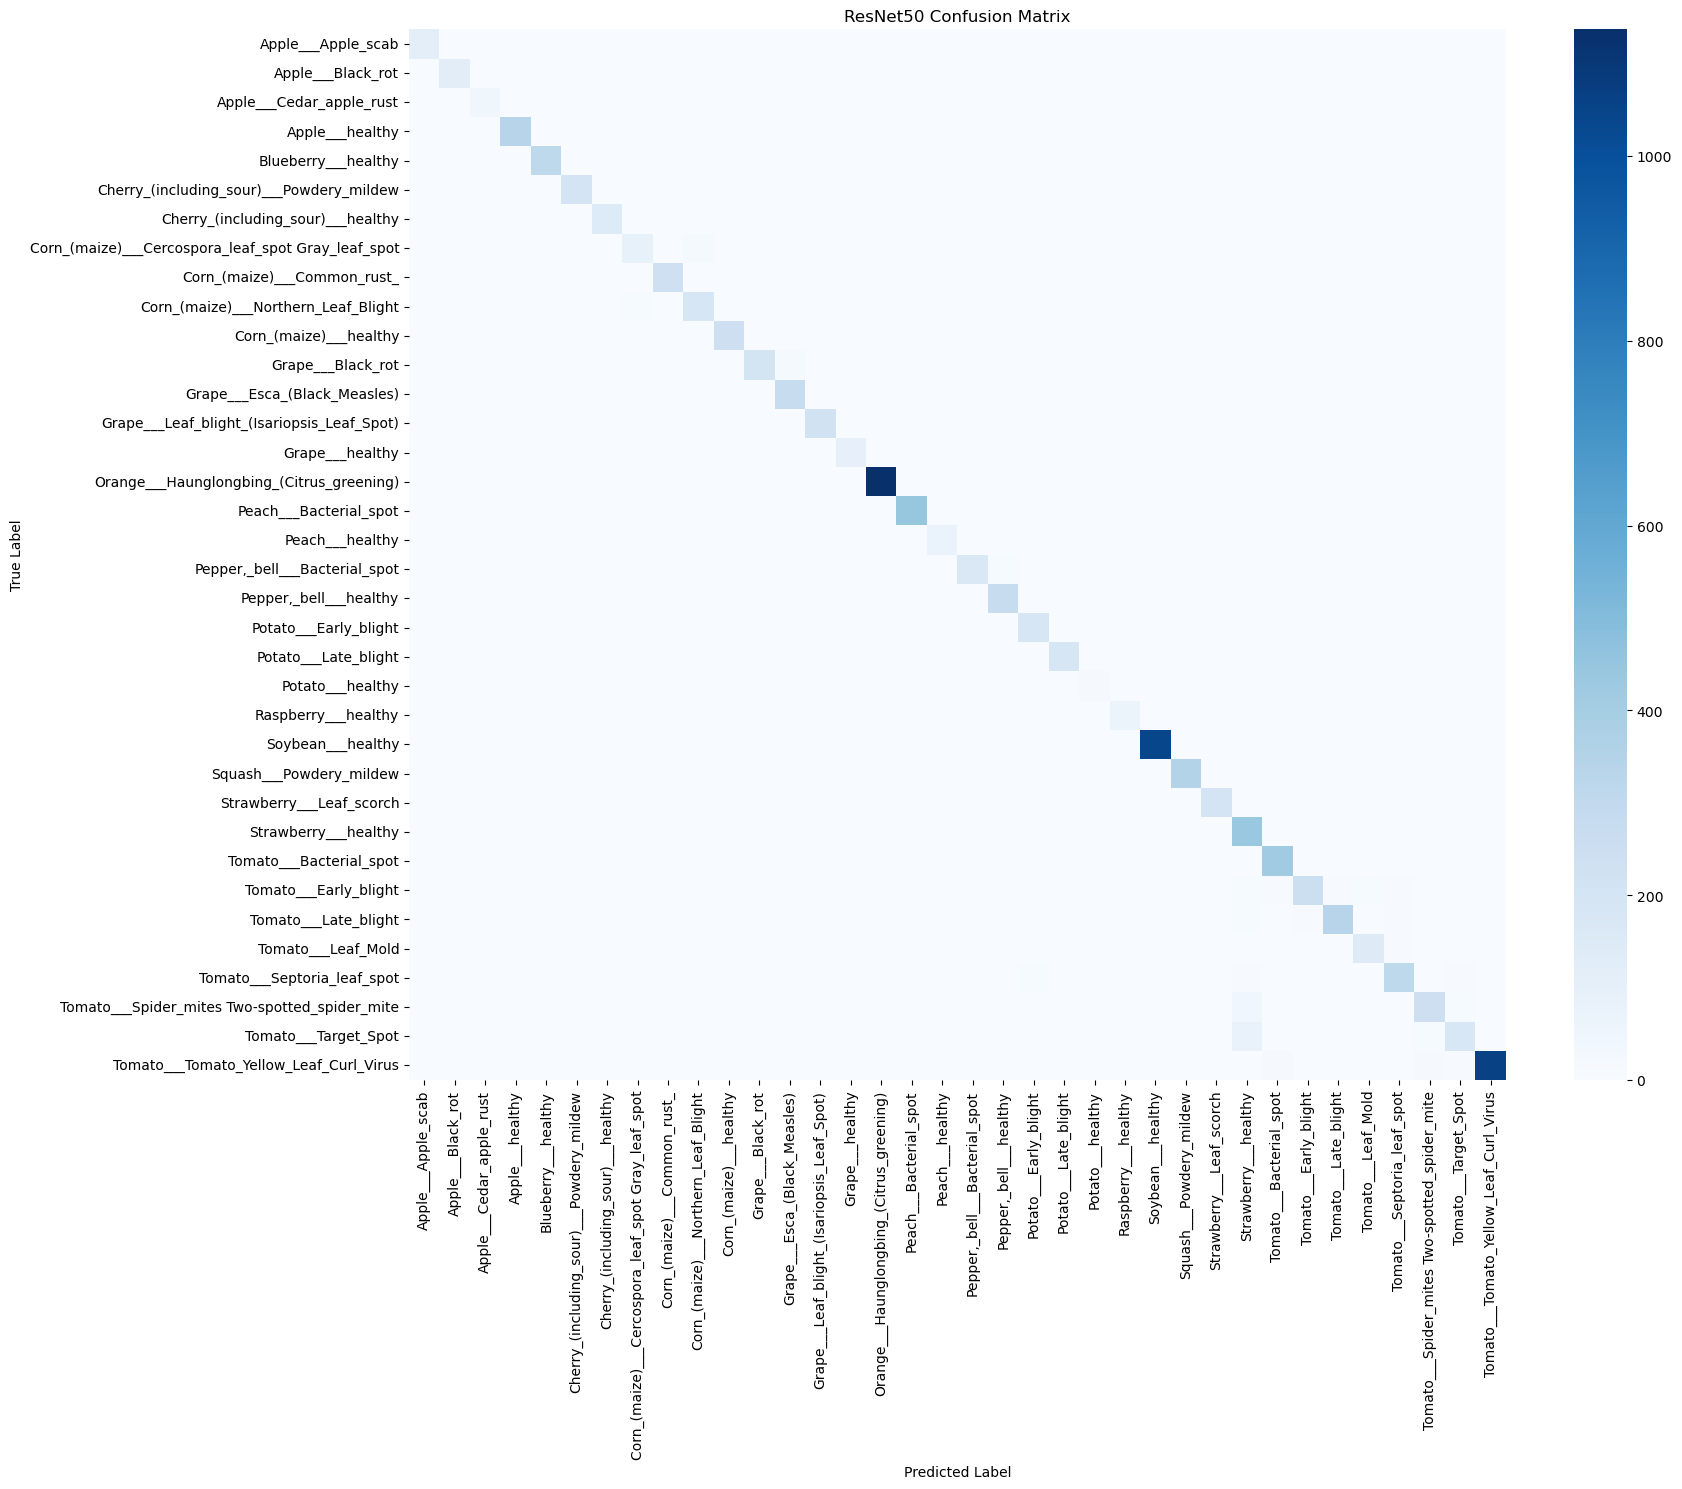

In [8]:
# ============================================================
# CONFUSION MATRIX FOR RESNET50
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("Generating ResNet50 predictions...")

y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = resnet_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

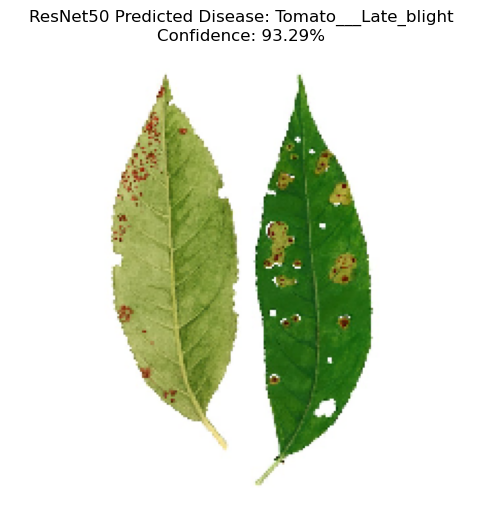

Predicted Disease: Tomato___Late_blight
Confidence: 93.29%


In [10]:
# ============================================================
# RESNET50 - SINGLE IMAGE PREDICTION
# ============================================================

from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Load the test image
img = load_img("test_leaf.jpg", target_size=(224, 224))

# Convert image to array
img_array = img_to_array(img)

# Normalize pixel values
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Make prediction using ResNet50
prediction = resnet_model.predict(img_array, verbose=0)

# Get predicted class
predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]

# Get confidence
confidence = prediction[0][predicted_index] * 100

# Display image and result
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")

plt.title(
    f"ResNet50 Predicted Disease: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

print("Predicted Disease:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

In [12]:
# ============================================================
# GET TREATMENT RECOMMENDATION FOR RESNET50 PREDICTION
# ============================================================

# Search for the predicted disease
result = treatment_df[
    treatment_df["Disease"].str.strip().str.lower()
    == predicted_class.strip().lower()
]

if not result.empty:
    print("Treatment Recommendation:")
    display(result)

else:
    print("No exact treatment information found for:", predicted_class)

    # Try a partial match
    partial_result = treatment_df[
        treatment_df["Disease"].str.contains(
            predicted_class.split("___")[-1],
            case=False,
            na=False
        )
    ]

    if not partial_result.empty:
        print("\nPossible matching records:")
        display(partial_result)
    else:
        print("No matching disease found in the treatment database.")

Treatment Recommendation:


,Disease,Crop,Symptoms,Treatment,Prevention,Source
30,Tomato___Late_blight,Tomato,"Dark, water-soaked lesions on leaves and stems...",Remove severely infected material where practi...,"Use healthy transplants, avoid overhead irriga...",https://extension.umn.edu/disease-management


In [13]:
# ============================================================
# COMPLETE RESNET50 PREDICTION AND TREATMENT REPORT
# ============================================================

print("=" * 60)
print("PLANT DISEASE DETECTION REPORT - RESNET50")
print("=" * 60)

print("\nPredicted Disease:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

if not result.empty:
    record = result.iloc[0]

    print("\nCrop:", record["Crop"])

    print("\nSymptoms:")
    print(record["Symptoms"])

    print("\nTreatment:")
    print(record["Treatment"])

    print("\nPrevention:")
    print(record["Prevention"])

    print("\nSource:")
    print(record["Source"])

else:
    print("\nNo treatment information available.")

print("\n" + "=" * 60)

PLANT DISEASE DETECTION REPORT - RESNET50

Predicted Disease: Tomato___Late_blight
Confidence: 93.29%

Crop: Tomato

Symptoms:
Dark, water-soaked lesions on leaves and stems; white growth may develop under humid conditions.

Treatment:
Remove severely infected material where practical and follow local disease alerts and approved disease-management recommendations.

Prevention:
Use healthy transplants, avoid overhead irrigation, monitor disease forecasts, and remove infected plant debris.

Source:
https://extension.umn.edu/disease-management

